In [1]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
#from langchain_community.document_loaders import PyPDFLoader 
# # for image + table+ text kind of. data use --> unstructured.io libraries
from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
#from langchain_community.vectorstores import Chroma
from langchain_chroma import Chroma
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from pydantic import BaseModel
load_dotenv()

True

In [2]:
# pip install tavily

In [3]:
from langgraph.prebuilt import ToolNode
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from typing import Annotated, operator
from langchain_core.tools import tool
from tavily import TavilyClient

In [4]:
# step 1 load the document:
pdf_reader = PdfReader("./documents/evs_oil_price_shock.pdf")

text = ""
for page in pdf_reader.pages:
    text += page.extract_text() + "\n"

print(text[:500])


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
docs = [Document(page_content=text)]

chunks = text_splitter.split_documents(docs)

print(len(chunks))

Will EVs Dampen the Oil Price
 Shock?
Electric Vehicles, Oil Demand Destruction, and the Future of Energy Price
 Volatility
 Version 1.0   |   April 2026
 Technical Reference Document

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 2
Table of Contents
3
Executive Summary
 4
1. Introduction
  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  .  . 4
1.1 Scope and Methodology
 5
2. Oil 
51


In [5]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
    # persist_directory="../chroma_db". # this is optional for this run
)

vectorstore.add_documents(chunks)

['1ddd7061-fc34-40ec-b5d1-faaf35bd33ac',
 'b4dc40a9-2af7-4c92-9871-47d59d5e1f49',
 '547ef119-0dfc-4f96-8e8e-19df91cfa0c9',
 '86483950-7aa4-475d-b8e4-5e93e0dc75c7',
 '2d56e910-6a09-4d6b-adf3-593bfc6d8524',
 'f5a24636-5489-471b-872a-48535a98d1ab',
 'd4320f52-62ea-4442-a0b9-2fb536066b2a',
 '80f59c49-3051-4b14-8b5b-c206d3f62114',
 'a6bb75e0-6d9a-475d-9060-2c8f24f33a9b',
 'cffde4a0-180e-467f-a4ae-f9307a2763ae',
 '43b98f4b-1fd1-4a93-976c-df25eb72107b',
 '9ffdd418-02e9-452b-a889-57025735556a',
 'a1dfe095-9983-40ec-845b-c689cc0c7de2',
 'b2fccf03-d2b7-4a53-81d3-c8fbb1c7e291',
 '9b67a142-3046-41d9-994e-afcd401a1e9b',
 '5da71100-22f8-43a8-a444-23d2c300e62a',
 '85ed4865-75ed-47aa-a360-2685aa466b35',
 '4cc9f73b-a406-4fea-a316-86f3187a1bf2',
 '342c0ffe-dfad-449b-8376-f31b19fbf7f4',
 'e60f880f-4ec2-4887-bde5-3e4c5e9de5cb',
 '003b5484-9a9e-4a31-818d-6c71d82a4dec',
 '6168e1ee-5496-445c-8f8b-80a9518a64a7',
 '3ec9e89a-fe2f-4a77-a8ba-247c60bc6ae5',
 '022f1d4e-2a1b-4b18-a63e-bb065043818a',
 '66ff1cba-d9b9-

In [6]:
llm = ChatOpenAI(model="gpt-4o-mini") # this is for route_questions and generation
agent_llm = ChatOpenAI(model="gpt-5-mini") 

In [7]:
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool



class RouteDecision(BaseModel):
    needs_retrieval: bool

In [8]:
# Define the tools
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k:int = 3):
    """ 
    Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages.
    
    """

    retriever = vectorstore.as_retriever(search_kwargs={"k": k})
    docs = retriever.invoke(query)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return context,docs


import os

@tool(response_format="content_and_artifact")
def web_search(query:str, max_results:int = 3):
    """
    Search the web for relevant information.
    Adjust max_results (default 3) to retrieve more or fewer results.
    """
    client = TavilyClient(api_key=os.getenv("TVLY_API_KEY"))
    response = client.search(query, max_results=max_results)
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return content, docs

In [9]:
tools = [web_search, vector_store_search]
agent_llm_with_tools = agent_llm.bind_tools(tools)
tool_node = ToolNode(tools)

In [22]:
agent_llm.invoke('tell me todays news')

AIMessage(content='I can’t fetch live news — my training only goes to June 2024 and I don’t have real‑time browsing. I can still help in a few useful ways; tell me which you prefer:\n\nOptions\n- Paste or link any article(s) and I’ll summarize, explain, or check claims.\n- Tell me your location and topics (e.g., world, US, tech, business, climate, sports). I’ll create a short, tailored “today’s headlines” briefing you can open sources for.\n- I can give a quick list of reliable news sites and how to set up alerts/feeds so you can get live updates.\n- I can explain how to spot misinformation and verify breaking stories.\n\nReliable sources (open any in your browser for current headlines)\n- Reuters: https://www.reuters.com\n- Associated Press: https://apnews.com\n- BBC News: https://www.bbc.com/news\n- The New York Times: https://www.nytimes.com\n- The Guardian: https://www.theguardian.com\n- Al Jazeera: https://www.aljazeera.com\n- Google News: https://news.google.com\n- Bloomberg (bus

In [24]:
agent_llm_with_tools.invoke('tell me todays news').tool_calls


[{'name': 'web_search',
  'args': {'query': 'November 17 2026 news headlines', 'max_results': 6},
  'id': 'call_0LgAsq4NZpvlTt3ydJ07kOVD',
  'type': 'tool_call'}]

In [11]:
def route_question(state: AgenticRAGState) -> dict:

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [12]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

In [13]:
def agent(state: AgenticRAGState) -> dict:
    messages = state['messages']
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]
        
    response = agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}
    

def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [14]:
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [15]:
from typing import Literal
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

In [16]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "agent")
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)


graph = graph_builder.compile()

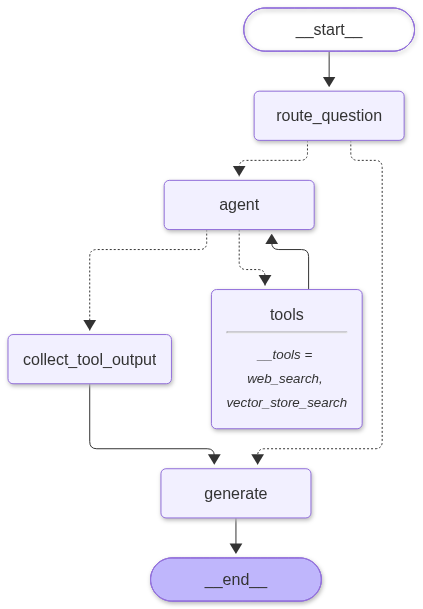

In [17]:
graph

In [18]:
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

In [19]:
result_vs

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 114, 'prompt_tokens': 438, 'total_tokens': 552, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ElDhZuSUIyxrlY9OU9KZYLZJIneX3', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1e9bc-4a66-7592-9687-ebe66e43bf16-0', tool_calls=[{'name': 'vector_store_search', 'args': {'query': 'how will adoption of electric vehicles impact oil demand displacement scenarios oil demand reduction fleet turnover projections through 2050', 'k': 6}, 'id': 'call_jIHMKhPfzaLJcxqezBt30tbP

In [20]:
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})


In [21]:
result_web

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 97, 'prompt_tokens': 431, 'total_tokens': 528, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ElDiAUhXurir8FMuLKyBDENalZuzi', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1e9bc-d962-7175-953a-af7b088fc7d6-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'New Delhi current temperature now', 'max_results': 5}, 'id': 'call_bCzBsL5D5LttN3JQefxpMnx6', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 431, 'output_tokens': 97, 

In [26]:
# case 3: both tools -  requires document context and current web data
query_both ="compare what EV report projects for 2030 oil demand and also tell me about the weather in India"

In [27]:
result_web_vector = graph.invoke({"query": query_both, "messages": [], "retrieved_docs": [], "context": ""})

In [28]:
result_web_vector

{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 479, 'prompt_tokens': 442, 'total_tokens': 921, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 384, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ElDvzap71kdwjMlxyFlJ5UtbwCmzB', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1e9c9-eaa7-71ff-9bea-1252cc3deb09-0', tool_calls=[{'name': 'vector_store_search', 'args': {'query': '2030 oil demand projection 2030 Will EVs Dampen the Oil Price Shock? oil demand displacement 2030', 'k': 5}, 'id': 'call_enbkSfwR5YmIAPALXtkYCt5z', 'type': 'tool_call'}, {'name': 'web_sea

In [29]:
print(result_web_vector['generation'])

The EV report projects that by the early 2030s, the penetration of electric vehicles (EVs) will likely become economically significant, potentially affecting oil demand dynamics. Particularly, the behavior of OPEC+ production policy in response to this change will be crucial. If OPEC producers struggle to agree on quota volumes in a declining demand environment, this could lead to a significant reduction in oil prices, accelerating the demand destruction from EV adoption.

In India, the current weather indicates a smoky haze in New Delhi with a temperature of 21.5°C and humidity at 43%. Different cities across India are experiencing varied weather conditions, with mentions of mist in Chennai, haze in Kolkata, and clear sky in Pune. Additionally, there are ongoing alerts for heavy rainfall and thunderstorms in several states, as forecasted by the India Meteorological Department (IMD).
